## 1. Import Libraries

Import the Python libraries required for data processing, visualization, and model evaluation.

- `pandas` and `numpy` are used for data manipulation and numerical operations.
- `matplotlib` is used to visualize model performance and seasonal patterns.
- `sklearn.metrics` provides classification and probability-based evaluation metrics.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

from IPython.display import display

## 2. Set the Data Directory

The merged weekly dataset (`merged_weekly_sarasota.csv`) is stored in the same folder as this notebook. Results are written to a `results/` subfolder there.

In [2]:
# Folder containing this notebook and the merged dataset
DATA_DIR = os.getcwd()
DATA_FILE = os.path.join(DATA_DIR, "merged_weekly_sarasota.csv")

if not os.path.exists(DATA_FILE):
    raise FileNotFoundError(
        f"Dataset not found: {DATA_FILE}. "
        "Run the notebook from the folder that contains merged_weekly_sarasota.csv."
    )

print(f"Working directory: {DATA_DIR}")
print(os.listdir(DATA_DIR))

Working directory: c:\Users\nadel\AI STUDIO
['merged_weekly_sarasota.csv', 'SeasonalClimatology.ipynb']


### Insights: Data Directory

- The merged dataset was found next to the notebook, so the notebook is portable as long as it runs from this folder.
- The folder contains only the dataset and this notebook. All outputs go to `results/seasonal_climatology/`, which keeps derived files separate from the source data.

## 3. Load and Inspect the Dataset

Load the merged weekly Sarasota dataset containing environmental observations and HAB forecasting targets.

The `week_ending` column is converted to datetime format, and observations are sorted chronologically.

The notebook also verifies that the required date and target columns are present:

- `target_1w`: HAB occurrence one week ahead.
- `target_2w`: HAB occurrence two weeks ahead.
- `target_4w`: HAB occurrence four weeks ahead.

The dataset dimensions and date range are displayed to verify successful loading.

In [3]:
# Load the existing merged weekly dataset
dataset = pd.read_csv(DATA_FILE)

# Convert dates and sort chronologically
dataset["week_ending"] = pd.to_datetime(
    dataset["week_ending"]
)

dataset = (
    dataset
    .sort_values("week_ending")
    .reset_index(drop=True)
)

# Verify required columns
required_cols = [
    "week_ending",
    "target_1w",
    "target_2w",
    "target_4w"
]

missing_cols = [
    col for col in required_cols
    if col not in dataset.columns
]

if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

print("Dataset shape:", dataset.shape)
print("Date range:", dataset["week_ending"].min(),
      "to", dataset["week_ending"].max())

display(dataset.head())

Dataset shape: (853, 89)
Date range: 2010-01-03 00:00:00 to 2026-05-03 00:00:00


,week_ending,kb_n_samples,kb_max,kb_max_log,kb_p95_log,kb_mean_log,kb_frac_1e4,kb_frac_1e5,rkb_max_log,rkb_frac_1e5,...,wind_u_4w,ksrq_air_temp_c,pressure_mb,grid_uwnd,grid_uwnd_4w,woy_sin,woy_cos,target_1w,target_2w,target_4w
0,2010-01-03,33,2000.0,3.301247,3.000434,2.348718,0.0,0.0,4.307517,0.000000,...,NaN,NaN,NaN,NaN,NaN,0.098579,0.995129,0.0,0.0,0.0
1,2010-01-10,31,0.0,0.000000,0.000000,0.000000,0.0,0.0,5.086363,0.015152,...,NaN,NaN,NaN,NaN,NaN,0.120123,0.992759,0.0,0.0,0.0
2,2010-01-17,65,1000.0,3.000434,0.000000,1.502007,0.0,0.0,3.222976,0.000000,...,NaN,NaN,NaN,NaN,NaN,0.238506,0.971141,0.0,0.0,0.0
3,2010-01-24,31,1000.0,3.000434,0.000000,1.521897,0.0,0.0,3.000434,0.000000,...,NaN,NaN,NaN,NaN,NaN,0.353435,0.935459,0.0,0.0,0.0
4,2010-01-31,34,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000,...,NaN,NaN,NaN,NaN,NaN,0.463246,0.886230,0.0,0.0,0.0


### Insights: Dataset

- **The dataset has 853 weekly records and 89 columns,** running from 2010-01-03 to 2026-05-03 (about 16.3 years).
- **It combines *K. brevis* cell-count summaries** (`kb_*`, `rkb_*`), **meteorological and oceanographic features** (winds, air temperature, pressure) and **seasonal encodings** (`woy_sin`, `woy_cos`).
- **Many meteorological columns are empty in early 2010.** Feature coverage is uneven over time. This does not affect this notebook, because the climatology uses only the date and target columns, but it will matter for the ML models.
- **Cell counts in the first weeks are low** (max ≤ 2,000 cells/L) and all targets are 0. This is consistent with a non-bloom winter.

## 4. Define Evaluation Parameters

Establish the forecasting horizons, target columns, evaluation years, and the climatology / threshold settings.

Three forecasting horizons are evaluated: 1, 2 and 4 weeks.

Evaluation uses an August–July bloom-year definition. For example, bloom year 2016 covers August 2015 through July 2016.

**Smoothing.** Each calendar week only has ~5–12 labelled training observations, so raw weekly frequencies are very noisy (many exact 0s). Two corrections are applied:

- `SMOOTHING_WINDOW`: counts are pooled over ±k neighbouring calendar weeks (circular, so week 52 neighbours week 1).
- `PRIOR_STRENGTH`: the pooled estimate is shrunk toward the overall training bloom rate using a Beta prior worth this many pseudo-observations.

**Threshold.** HABs occur in only ~15% of weeks, so a fixed 0.5 threshold never produces a positive prediction (recall = 0). Instead, the threshold is chosen **separately in each fold using training data only** (`THRESHOLD_METHOD`):

- `"train_f1"`: threshold that maximises F1 on the training observations.
- `"train_prevalence"`: the training-period bloom rate.
- `"fixed"`: `FIXED_THRESHOLD`.

In [4]:
HORIZONS = [1, 2, 4]

TARGET_COLS = {
    1: "target_1w",
    2: "target_2w",
    4: "target_4w"
}

TEST_YEARS = range(2016, 2027)

# Climatology smoothing
SMOOTHING_WINDOW = 3     # pool counts over +/- 3 calendar weeks
PRIOR_STRENGTH = 10      # Beta-prior pseudo-observations toward the overall rate

# Classification threshold (selected from training data in each fold)
THRESHOLD_METHOD = "train_f1"   # "train_f1", "train_prevalence" or "fixed"
FIXED_THRESHOLD = 0.5

# Results directory
OUTPUT_DIR = os.path.join(DATA_DIR, "results", "seasonal_climatology")

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Forecasting horizons:", HORIZONS)
print("Test years:", list(TEST_YEARS))
print("Smoothing window: +/-", SMOOTHING_WINDOW, "weeks | prior strength:", PRIOR_STRENGTH)
print("Threshold method:", THRESHOLD_METHOD)

Forecasting horizons: [1, 2, 4]
Test years: [2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]
Smoothing window: +/- 3 weeks | prior strength: 10
Threshold method: train_f1


### Insights: Evaluation Setup

- **The setup gives 33 folds:** 11 bloom years (2016–2026) × 3 horizons.
- **The August–July bloom year keeps each autumn/winter bloom season inside one test fold** rather than splitting it across two calendar years.
- **The 2026 fold is partial** (data ends May 2026), so its results cover only part of the year.
- **Smoothing over ±3 weeks with a prior of 10 pseudo-observations is fairly strong.** Expect smooth, conservative probabilities that stay close to the overall bloom rate.

## 5. Calculate Seasonal Climatology Probabilities

Define a function that estimates the historical probability of HAB occurrence for each calendar week of the **target** date (forecast origin + horizon).

For each calendar week *w*:

1. Count HAB occurrences and observations in the training data for weeks *w − k … w + k* (circular window).
2. Shrink toward the overall training bloom rate *p̄* with a Beta prior of strength *m*:

   P(HAB | week *w*) = (window occurrences + *m*·*p̄*) / (window observations + *m*)

Weeks with little data therefore fall back smoothly to the overall rate instead of jumping to 0 or 1. Only training observations are used.

The function returns the weekly table (raw and smoothed probabilities) and the overall training-period probability. A helper also selects the classification threshold from training data only.

In [5]:
def get_target_week(dates):
    # ISO calendar week, with week 53 merged into week 52
    return dates.dt.isocalendar().week.astype(int).clip(upper=52)


def calculate_seasonal_climatology(
    training_data,
    target_col,
    horizon,
    window=SMOOTHING_WINDOW,
    prior_strength=PRIOR_STRENGTH
):
    # Smoothed historical HAB probability for each target calendar week.
    # Uses training observations only.

    historical_data = training_data.copy()

    historical_data["target_date"] = (
        historical_data["week_ending"] +
        pd.to_timedelta(7 * horizon, unit="D")
    )
    historical_data["target_week"] = get_target_week(
        historical_data["target_date"]
    )

    # Raw counts for every calendar week (0 where no data)
    weekly = (
        historical_data
        .groupby("target_week")[target_col]
        .agg(HAB_occurrences="sum", total_observations="count")
        .reindex(range(1, 53), fill_value=0)
    )
    weekly.index.name = "target_week"

    overall_probability = float(historical_data[target_col].mean())

    occurrences = weekly["HAB_occurrences"].to_numpy(dtype=float)
    observations = weekly["total_observations"].to_numpy(dtype=float)

    # Pool counts over a circular +/- window of calendar weeks
    window_occurrences = np.zeros(52)
    window_observations = np.zeros(52)

    for offset in range(-window, window + 1):
        window_occurrences += np.roll(occurrences, offset)
        window_observations += np.roll(observations, offset)

    # Beta-prior shrinkage toward the overall training rate
    denominator = window_observations + prior_strength

    smoothed = np.divide(
        window_occurrences + prior_strength * overall_probability,
        denominator,
        out=np.full(52, overall_probability),
        where=denominator > 0
    )

    climatology = weekly.reset_index()

    climatology["raw_probability"] = np.divide(
        occurrences,
        observations,
        out=np.full(52, np.nan),
        where=observations > 0
    )
    climatology["window_occurrences"] = window_occurrences
    climatology["window_observations"] = window_observations
    climatology["HAB_probability"] = smoothed

    return climatology, overall_probability


def choose_threshold(
    y_true,
    y_probability,
    overall_probability,
    method=THRESHOLD_METHOD
):
    # Select a classification threshold using TRAINING data only.

    if method == "fixed":
        return FIXED_THRESHOLD

    if method == "train_prevalence":
        return overall_probability

    # method == "train_f1"
    y_true = np.asarray(y_true).astype(int)
    y_probability = np.asarray(y_probability, dtype=float)

    if y_true.min() == y_true.max():
        return overall_probability

    best_threshold = overall_probability
    best_f1 = -1.0

    for candidate in np.unique(y_probability):
        f1 = f1_score(
            y_true,
            (y_probability >= candidate).astype(int),
            zero_division=0
        )
        if f1 >= best_f1:
            best_threshold, best_f1 = float(candidate), f1

    return best_threshold

### Insights: Climatology Function Design

- **Each probability is estimated for the target date's calendar week, not the forecast origin's.** This matches how the forecast is used: it predicts conditions *h* weeks ahead.
- **Week 53 is merged into week 52, and the smoothing window wraps around the year end,** so late-December and early-January weeks share information.
- **The Beta prior keeps weeks with little data from collapsing to 0 or 1.** It also sets a ceiling on how extreme any probability can get.
- **The F1-maximising threshold is fitted on training predictions only,** so no test-period information leaks into the threshold.

## 6. Define Evaluation Metrics

Create a function to evaluate the seasonal climatology predictions.

Predicted probabilities are converted into binary classifications using the fold-specific threshold selected from training data.

The following metrics are calculated:

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- PR-AUC
- Brier score
- False alarm rate

The confusion matrix is also used to obtain true positives, false positives, true negatives, and false negatives.

ROC-AUC and PR-AUC are only calculated when both classes are present in the evaluation data.

In [6]:
from sklearn.metrics import brier_score_loss


def evaluate_climatology(
    y_true,
    y_probability,
    threshold
):
    # Evaluate probabilistic HAB predictions at a given threshold.

    y_true = np.asarray(y_true).astype(int)
    y_probability = np.asarray(y_probability, dtype=float)

    y_pred = (y_probability >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)

    # AUC metrics require both classes
    if len(np.unique(y_true)) == 2:
        roc_auc = roc_auc_score(y_true, y_probability)
        pr_auc = average_precision_score(y_true, y_probability)
    else:
        roc_auc = np.nan
        pr_auc = np.nan

    false_alarm_rate = fp / (fp + tn) if (fp + tn) > 0 else np.nan

    return {
        "threshold": threshold,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "pr_auc": pr_auc,
        "roc_auc": roc_auc,
        "brier": brier_score_loss(y_true, y_probability),
        "false_alarm_rate": false_alarm_rate,
        "true_positives": tp,
        "false_positives": fp,
        "true_negatives": tn,
        "false_negatives": fn
    }

### Insights: Metric Choices

- **Use the probability-based metrics (ROC-AUC, PR-AUC, Brier) as the main measure of skill.** With ~15% prevalence, accuracy is dominated by the non-bloom majority. Threshold-based metrics depend on how the threshold was picked.
- **PR-AUC is the most informative ranking metric here.** For a no-skill model it equals the bloom rate (~0.15), which gives a clear bar to beat.
- **The false-alarm rate matters for operations.** Frequent false alarms erode trust in HAB warnings.

## 7. Evaluate Seasonal Climatology Using Forward Chaining

Evaluate the seasonal climatology baseline across all forecasting horizons and bloom years.

A forward-chaining approach is used to prevent future information from entering the training data.

For each evaluation year:

1. Define the August–July test period.
2. Select training observations whose future target dates occur strictly before the test period begins.
3. Calculate smoothed historical HAB probabilities using the training observations.
4. Select the classification threshold from the training observations.
5. Assign probabilities to test observations based on their future target calendar weeks.
6. Calculate and store evaluation metrics, individual predictions, and weekly climatology probabilities.

The training-fold bloom rate is also stored with each prediction as a constant-prevalence reference forecast for Section 19 (strictly out-of-sample).

In [7]:
# Store evaluation metrics and individual predictions
climatology_results = []
climatology_predictions = []
climatology_probabilities = []

for horizon in HORIZONS:

    target = TARGET_COLS[horizon]

    # Keep rows with a known binary target
    data = dataset.dropna(subset=[target, "week_ending"]).copy()
    data = data[data[target].isin([0, 1])].copy()
    data[target] = data[target].astype(int)

    data["target_date"] = (
        data["week_ending"] + pd.to_timedelta(7 * horizon, unit="D")
    )
    data["target_week"] = get_target_week(data["target_date"])

    for year in TEST_YEARS:

        test_start = pd.Timestamp(year=year - 1, month=8, day=1)
        test_end = pd.Timestamp(year=year, month=8, day=1)

        test_mask = (
            (data["week_ending"] >= test_start) &
            (data["week_ending"] < test_end)
        )

        # Training targets must be observed before the test period begins
        train_mask = data["target_date"] < test_start

        train_data = data.loc[train_mask].copy()
        test_data = data.loc[test_mask].copy()

        if len(train_data) == 0 or len(test_data) == 0:
            continue

        # Smoothed seasonal probabilities from training data
        climatology, overall_probability = calculate_seasonal_climatology(
            training_data=train_data,
            target_col=target,
            horizon=horizon
        )

        probability_lookup = (
            climatology.set_index("target_week")["HAB_probability"].to_dict()
        )

        # Threshold chosen from training data only
        train_probability = (
            train_data["target_week"]
            .map(probability_lookup)
            .fillna(overall_probability)
        )

        threshold = choose_threshold(
            y_true=train_data[target],
            y_probability=train_probability,
            overall_probability=overall_probability
        )

        # Test predictions
        test_data["predicted_probability"] = (
            test_data["target_week"]
            .map(probability_lookup)
            .fillna(overall_probability)
        )

        test_data["predicted_HAB"] = (
            test_data["predicted_probability"] >= threshold
        ).astype(int)

        # Constant-prevalence reference forecast (out-of-sample)
        test_data["constant_probability"] = overall_probability

        metrics = evaluate_climatology(
            y_true=test_data[target],
            y_probability=test_data["predicted_probability"],
            threshold=threshold
        )

        climatology_results.append({
            "horizon": horizon,
            "test_year": year,
            "model": "Seasonal Climatology",
            "num_training_observations": len(train_data),
            "num_test_observations": len(test_data),
            "num_test_blooms": int(test_data[target].sum()),
            **metrics
        })

        test_data["threshold"] = threshold
        test_data["horizon"] = horizon
        test_data["test_year"] = year
        test_data["model"] = "Seasonal Climatology"

        climatology_predictions.append(
            test_data[
                [
                    "week_ending",
                    "target_date",
                    "target_week",
                    target,
                    "predicted_probability",
                    "predicted_HAB",
                    "threshold",
                    "constant_probability",
                    "horizon",
                    "test_year",
                    "model"
                ]
            ].rename(columns={target: "actual_HAB"})
        )

        climatology["horizon"] = horizon
        climatology["test_year"] = year
        climatology_probabilities.append(climatology)

        print(
            f"{horizon}-week | {year} | "
            f"thr: {threshold:.3f} | "
            f"Acc: {metrics['accuracy']:.3f} | "
            f"Prec: {metrics['precision']:.3f} | "
            f"Rec: {metrics['recall']:.3f} | "
            f"F1: {metrics['f1']:.3f} | "
            f"Brier: {metrics['brier']:.3f}"
        )

print("\nSeasonal climatology evaluation completed.")

1-week | 2016 | thr: 0.097 | Acc: 0.647 | Prec: 0.500 | Rec: 0.250 | F1: 0.333 | Brier: 0.326
1-week | 2017 | thr: 0.199 | Acc: 0.750 | Prec: 0.000 | Rec: 0.000 | F1: 0.000 | Brier: 0.208
1-week | 2018 | thr: 0.141 | Acc: 0.605 | Prec: 0.125 | Rec: 0.111 | F1: 0.118 | Brier: 0.216
1-week | 2019 | thr: 0.134 | Acc: 0.931 | Prec: 0.000 | Rec: 0.000 | F1: 0.000 | Brier: 0.008
1-week | 2020 | thr: 0.118 | Acc: 0.667 | Prec: 0.071 | Rec: 0.250 | F1: 0.111 | Brier: 0.079
1-week | 2021 | thr: 0.114 | Acc: 0.333 | Prec: 0.105 | Rec: 0.182 | F1: 0.133 | Brier: 0.253
1-week | 2022 | thr: 0.129 | Acc: 1.000 | Prec: 1.000 | Rec: 1.000 | F1: 1.000 | Brier: 0.169
1-week | 2023 | thr: 0.129 | Acc: 0.800 | Prec: 0.000 | Rec: 0.000 | F1: 0.000 | Brier: 0.011
1-week | 2024 | thr: 0.135 | Acc: 0.848 | Prec: 0.000 | Rec: 0.000 | F1: 0.000 | Brier: 0.012
1-week | 2025 | thr: 0.128 | Acc: 0.757 | Prec: 0.375 | Rec: 0.429 | F1: 0.400 | Brier: 0.155
1-week | 2026 | thr: 0.125 | Acc: 0.513 | Prec: 0.000 | Rec:

### Insights: Forward-Chaining Evaluation

- **There are 33 evaluations in total** (11 bloom years × 3 horizons), and every fold had usable training and test data.
- **The selected thresholds are low (~0.10–0.20),** far below 0.5. This reflects the ~15% bloom prevalence and confirms that a fixed 0.5 threshold would never predict a bloom.
- **F1 is non-zero in only 6 of 11 years.** Results are inconsistent: the best real years are 2025 (F1 0.40) and 2016 (0.33), while 2017, 2019, 2023, 2024 and 2026 score 0.
- **2022's perfect score (all metrics = 1.0) is an artifact.** That fold has only 4 labelled test weeks.
- **The Brier score mostly tracks whether a year had blooms:**
  - About 0.01–0.02 in no-bloom years (2019, 2023, 2024, 2026), where small probabilities happen to be correct.
  - 0.25–0.33 in heavy bloom years (2016, 2021).
- **Horizon barely matters.** The 1-, 2- and 4-week results are nearly identical because the climatology depends only on the target calendar week.

## 8. Summarize Model Performance

Combine the evaluation results into a DataFrame and display performance for each forecasting horizon and test year.

A second summary table calculates the average performance across evaluation years for each forecasting horizon.

These results provide an initial comparison of seasonal climatology performance over time.

Annual averages should be interpreted carefully because the number of observations and HAB occurrences varies between evaluation years.

In [8]:
climatology_results_df = pd.DataFrame(climatology_results)

display(
    climatology_results_df.sort_values(["horizon", "test_year"])
    .reset_index(drop=True)
)

# Mean of annual metrics. Precision/recall/F1/AUC are only meaningful in
# years that contain at least one bloom, so those years are averaged
# separately from the all-years accuracy/Brier/false-alarm averages.
all_year_metrics = ["accuracy", "brier", "false_alarm_rate"]
bloom_year_metrics = ["precision", "recall", "f1", "pr_auc", "roc_auc"]

all_years_mean = (
    climatology_results_df
    .groupby(["horizon", "model"])[all_year_metrics]
    .mean()
)

bloom_years_mean = (
    climatology_results_df[climatology_results_df["num_test_blooms"] > 0]
    .groupby(["horizon", "model"])[bloom_year_metrics]
    .mean()
)

climatology_summary_df = (
    all_years_mean.join(bloom_years_mean).reset_index()
)

print("Average seasonal climatology performance "
      "(precision/recall/F1/AUC averaged over years with >= 1 bloom):")

display(climatology_summary_df.round(4))

,horizon,test_year,model,num_training_observations,num_test_observations,num_test_blooms,threshold,accuracy,precision,recall,f1,pr_auc,roc_auc,brier,false_alarm_rate,true_positives,false_positives,true_negatives,false_negatives
0,1,2016,Seasonal Climatology,264,34,12,0.096537,0.647059,0.500000,0.250000,0.333333,0.445393,0.465909,0.325794,0.136364,3,3,19,9
1,1,2017,Seasonal Climatology,298,24,6,0.198740,0.750000,0.000000,0.000000,0.000000,0.767593,0.805556,0.207558,0.000000,0,0,18,6
2,1,2018,Seasonal Climatology,322,38,9,0.140528,0.605263,0.125000,0.111111,0.117647,0.188796,0.268199,0.216167,0.241379,1,7,22,8
3,1,2019,Seasonal Climatology,361,29,0,0.133749,0.931034,0.000000,0.000000,0.000000,NaN,NaN,0.007523,0.068966,0,2,27,0
4,1,2020,Seasonal Climatology,389,48,4,0.117885,0.666667,0.071429,0.250000,0.111111,0.124275,0.536932,0.078514,0.295455,1,13,31,3
5,1,2021,Seasonal Climatology,437,39,11,0.114196,0.333333,0.105263,0.181818,0.133333,0.200257,0.220779,0.253096,0.607143,2,17,11,9
6,1,2022,Seasonal Climatology,477,4,1,0.128955,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.168936,0.000000,1,0,3,0
7,1,2023,Seasonal Climatology,481,5,0,0.129092,0.800000,0.000000,0.000000,0.000000,NaN,NaN,0.010752,0.200000,0,1,4,0
8,1,2024,Seasonal Climatology,486,33,0,0.134842,0.848485,0.000000,0.000000,0.000000,NaN,NaN,0.011538,0.151515,0,5,28,0
9,1,2025,Seasonal Climatology,518,37,7,0.128176,0.756757,0.375000,0.428571,0.400000,0.341740,0.642857,0.154847,0.166667,3,5,25,4


Average seasonal climatology performance (precision/recall/F1/AUC averaged over years with >= 1 bloom):


,horizon,model,accuracy,brier,false_alarm_rate,precision,recall,f1,pr_auc,roc_auc
0,1,Seasonal Climatology,0.7138,0.1323,0.2141,0.311,0.3174,0.2993,0.4383,0.5629
1,2,Seasonal Climatology,0.7106,0.1334,0.2174,0.311,0.3174,0.2993,0.4388,0.5558
2,4,Seasonal Climatology,0.7200,0.1354,0.2078,0.311,0.3128,0.2992,0.4387,0.5421


### Insights: Performance Summary

- **Mean accuracy (~0.71) looks reasonable but is below a trivial baseline.** Always predicting "no bloom" would score about 0.85 (1 − 0.152 bloom rate).
- **The false-alarm rate is about 21%.** Across all 1-week folds the model made **72 false positives against 11 true positives**, catching 11 of 50 blooms. That is a pooled precision of ~0.13 and a pooled recall of ~0.22.
- **Bloom-year averages look modest:** precision ≈ 0.31, recall ≈ 0.32, F1 ≈ 0.30, ROC-AUC ≈ 0.54–0.56.
- **Those averages are inflated by 2022,** which scores perfectly on only 4 observations. Without 2022, mean F1 drops to ~0.18 and mean ROC-AUC to ~0.49, which is chance level.
- **The three horizons are almost identical** (F1 0.299 in every case), confirming that horizon is irrelevant for a calendar-only model.

## 9. Visualize Annual Classification Performance

Plot the annual performance of the seasonal climatology baseline for each forecasting horizon.

The following metrics are visualized:

- Accuracy
- F1-score
- Recall
- Precision

These plots help identify changes in model performance across bloom years and reveal whether the baseline performs consistently over time.

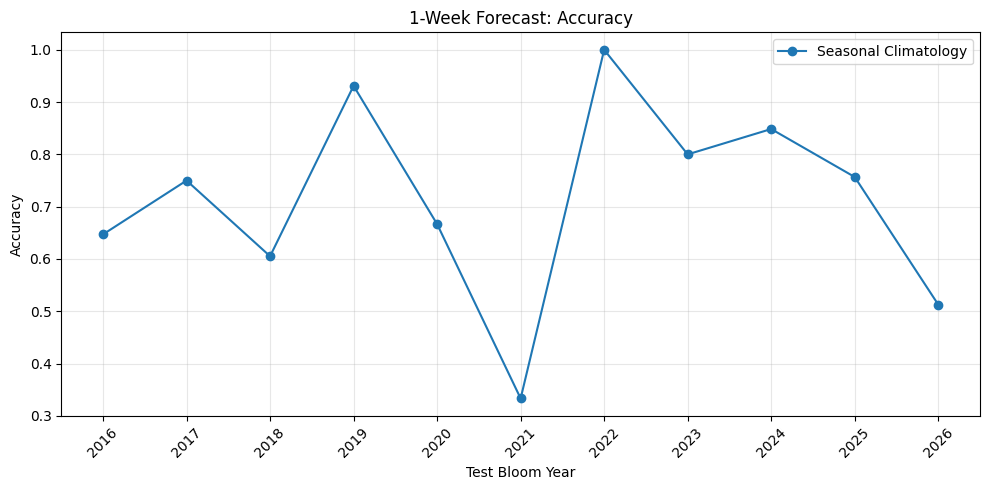

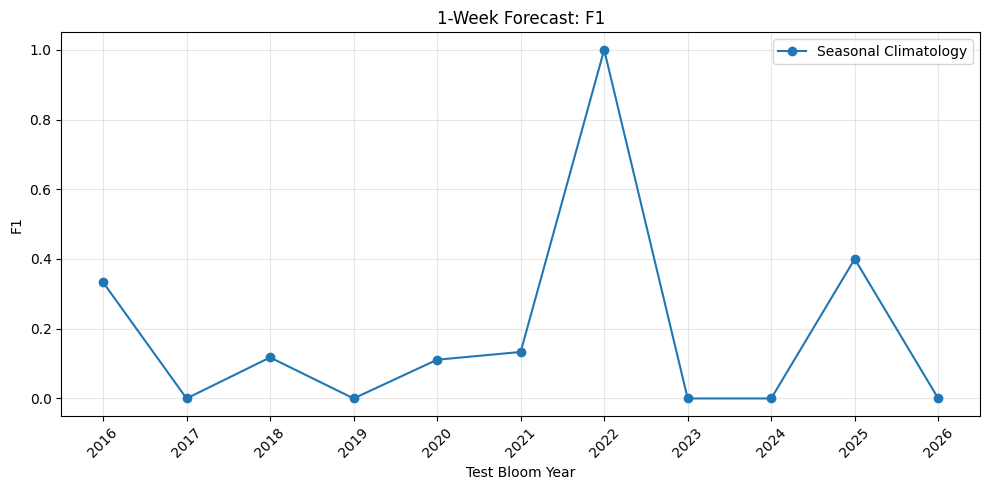

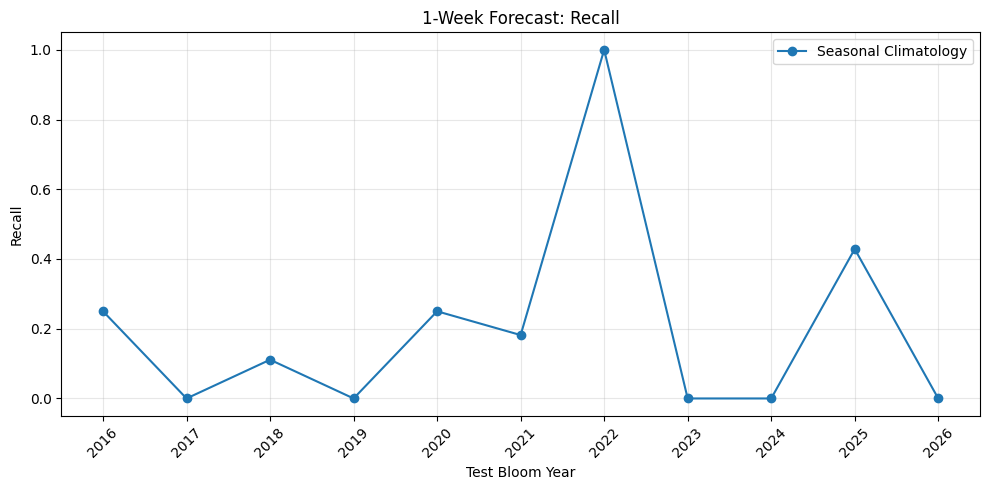

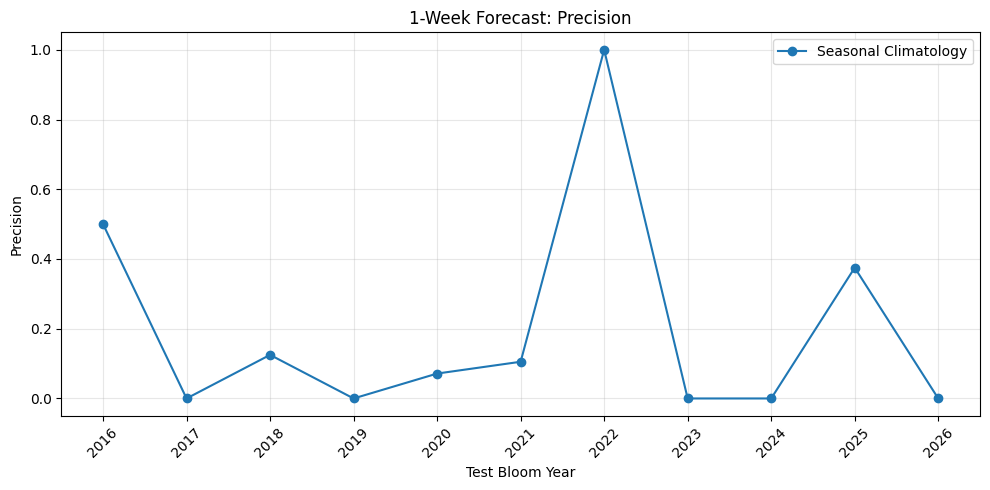

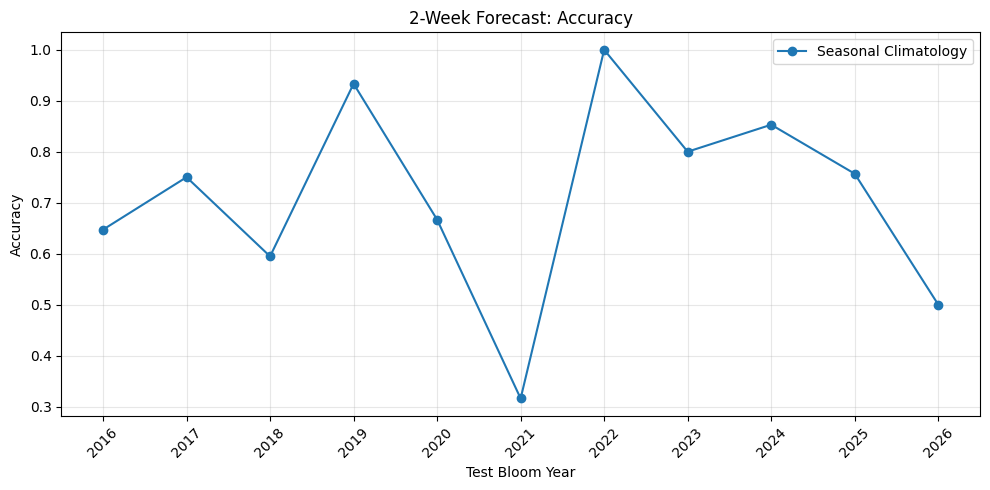

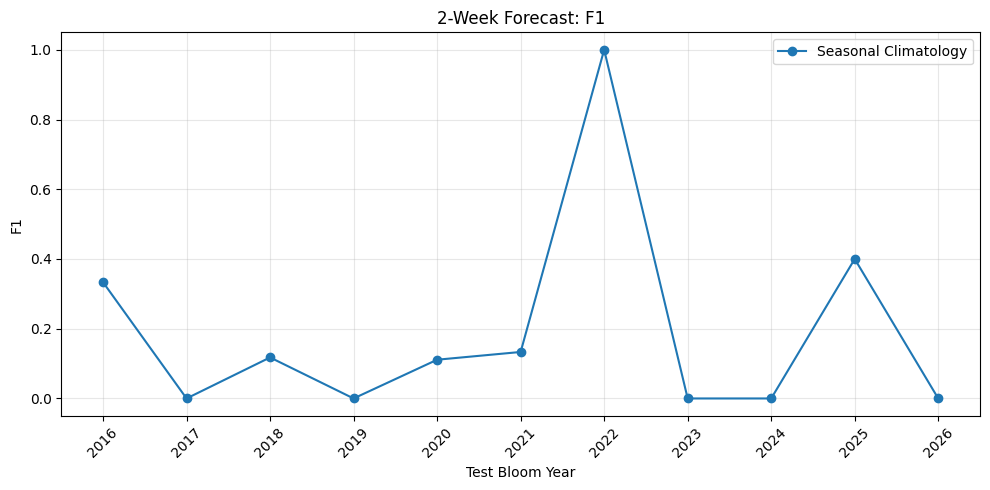

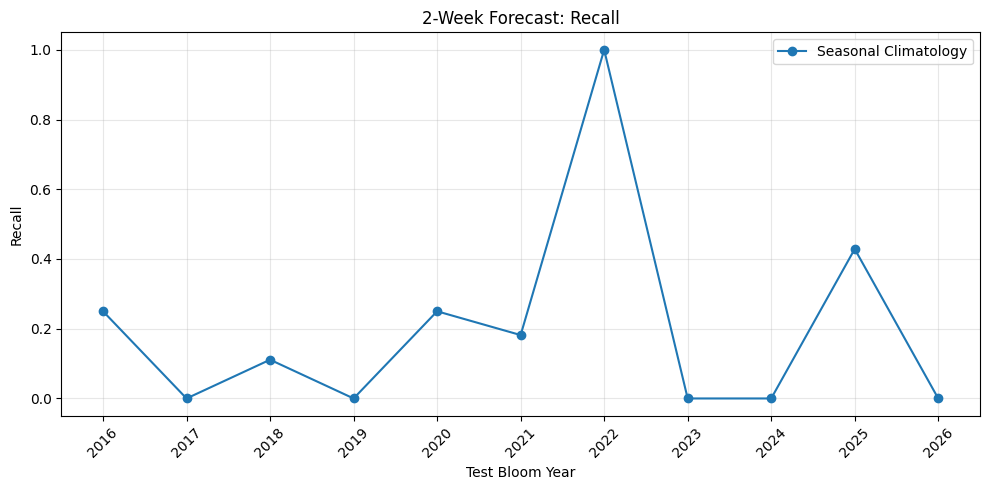

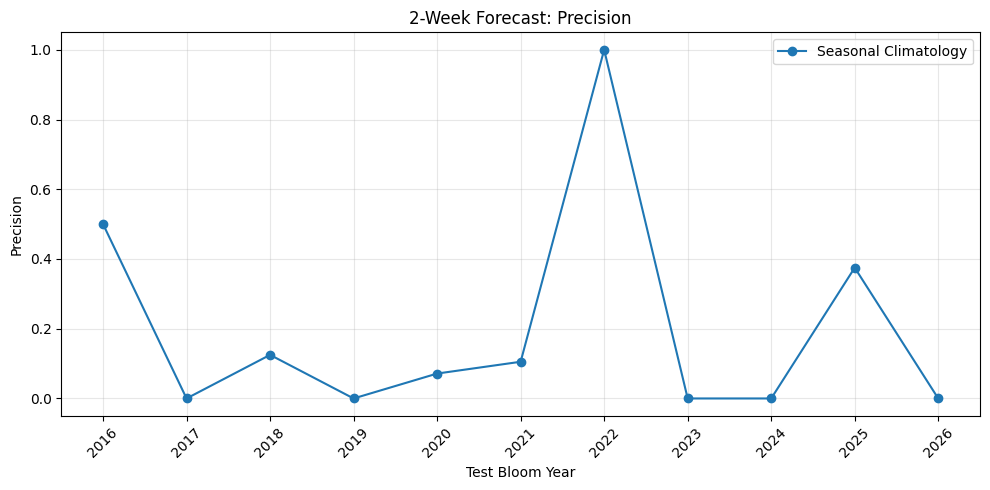

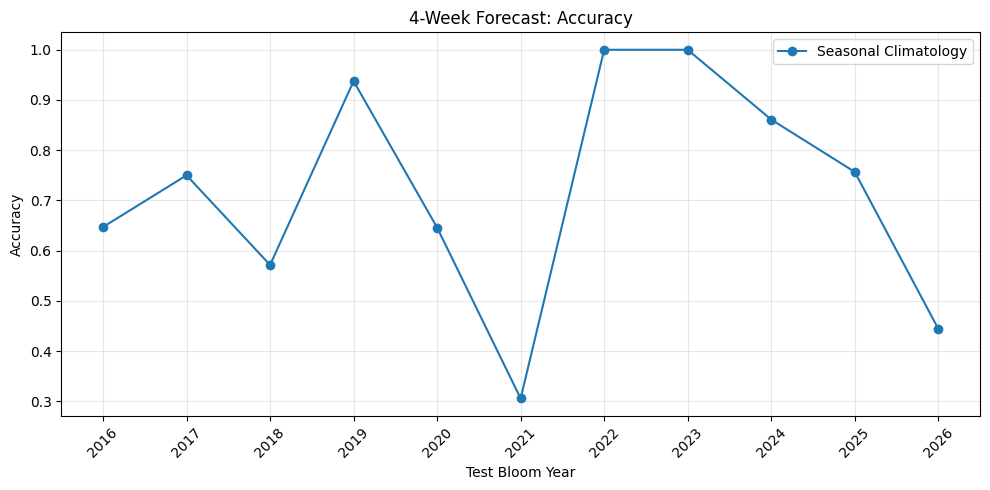

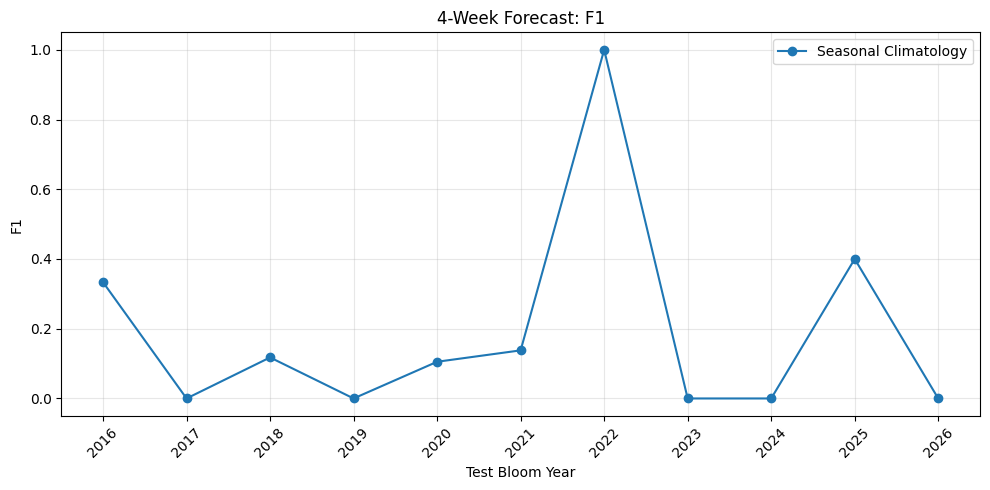

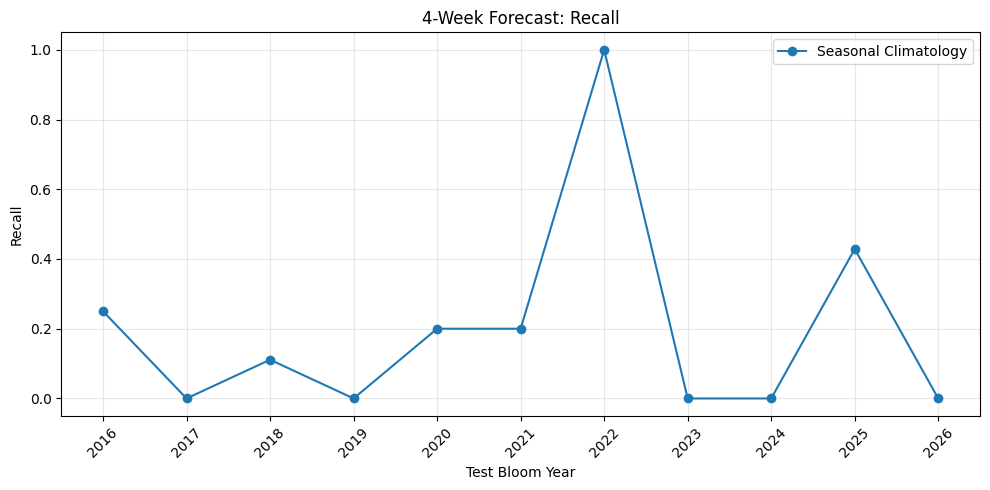

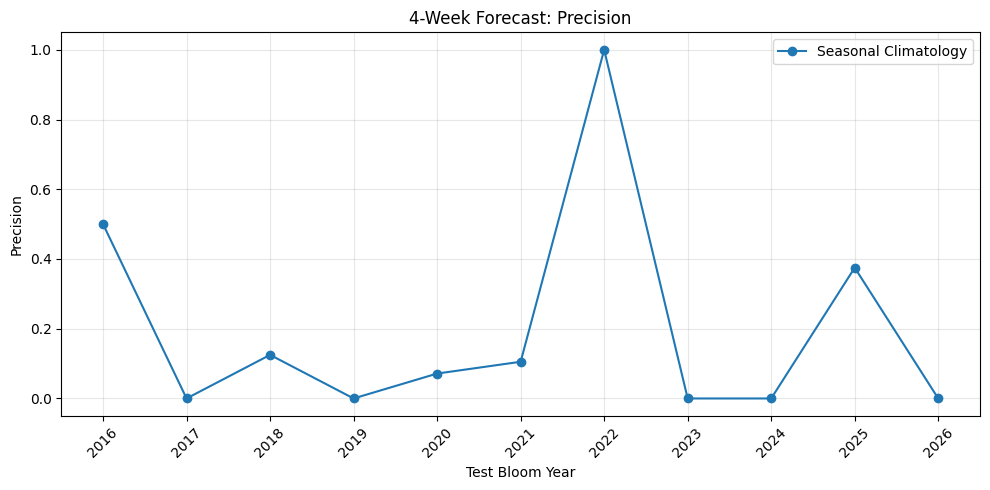

In [9]:
for horizon in HORIZONS:

    horizon_results = climatology_results_df[
        climatology_results_df["horizon"] == horizon
    ].sort_values("test_year")

    for metric in ["accuracy", "f1", "recall", "precision"]:

        plt.figure(figsize=(10, 5))

        plt.plot(
            horizon_results["test_year"],
            horizon_results[metric],
            marker="o",
            label="Seasonal Climatology"
        )

        plt.xlabel("Test Bloom Year")
        plt.ylabel(metric.replace("_", " ").title())

        plt.title(
            f"{horizon}-Week Forecast: "
            f"{metric.replace('_', ' ').title()}"
        )

        plt.xticks(
            list(TEST_YEARS),
            rotation=45
        )

        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

### Insights: Annual Performance Plots

- **Performance swings widely from year to year, with no upward trend** even as the training history grows from ~260 to ~555 weeks. More years of calendar data do not make this model better.
- **Accuracy ranges from ~0.31 (2021) to 1.0 (2022).** Low-accuracy years (2021, 2026) are caused by many false alarms during the autumn peak. High-accuracy years (2019, 2022, 2023) are mostly quiet years or very small samples.
- **F1, recall and precision are zero in 5 of 11 years.** Two kinds of years are behind this:
  - Years with no blooms (2019, 2023, 2024, 2026).
  - Years where blooms happened but none were caught (2017).
- **The 2022 spike to 1.0 on every metric comes from a single correct prediction** out of 4 observations.
- **The 1-, 2- and 4-week lines are almost the same.** The plots look the same across horizons because the climatology hardly changes with horizon.

## 10. Visualize Seasonal HAB Probabilities

Visualize the estimated historical HAB probability for each calendar week.

For each forecasting horizon, probabilities from the evaluation folds are grouped by target calendar week and averaged.

The resulting plots illustrate the seasonal patterns learned by the climatology baseline and identify periods of the year associated with higher historical HAB occurrence frequencies.

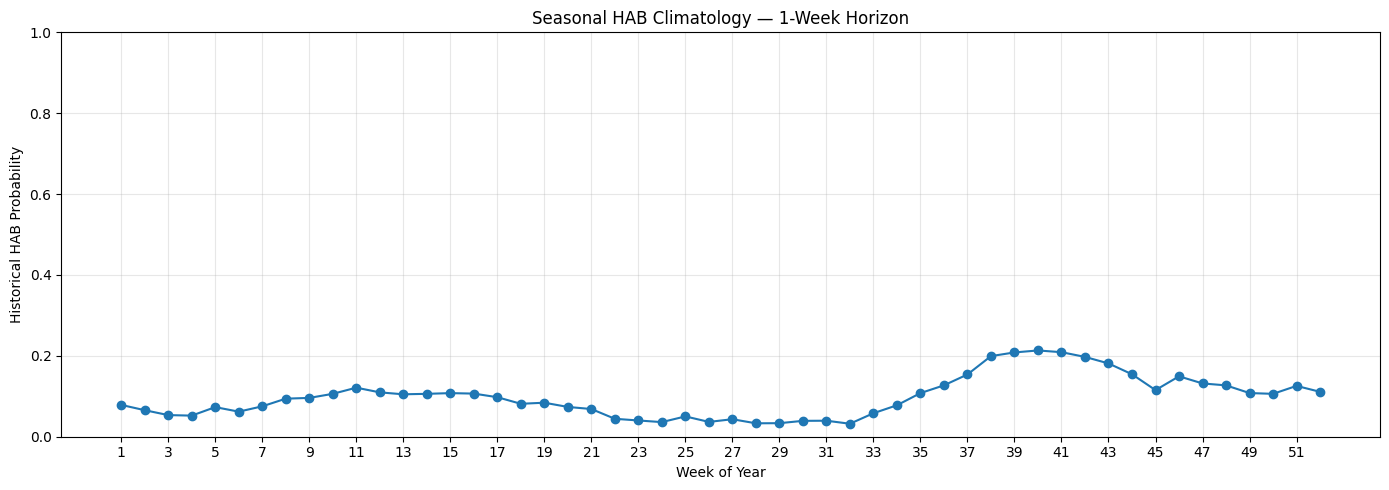

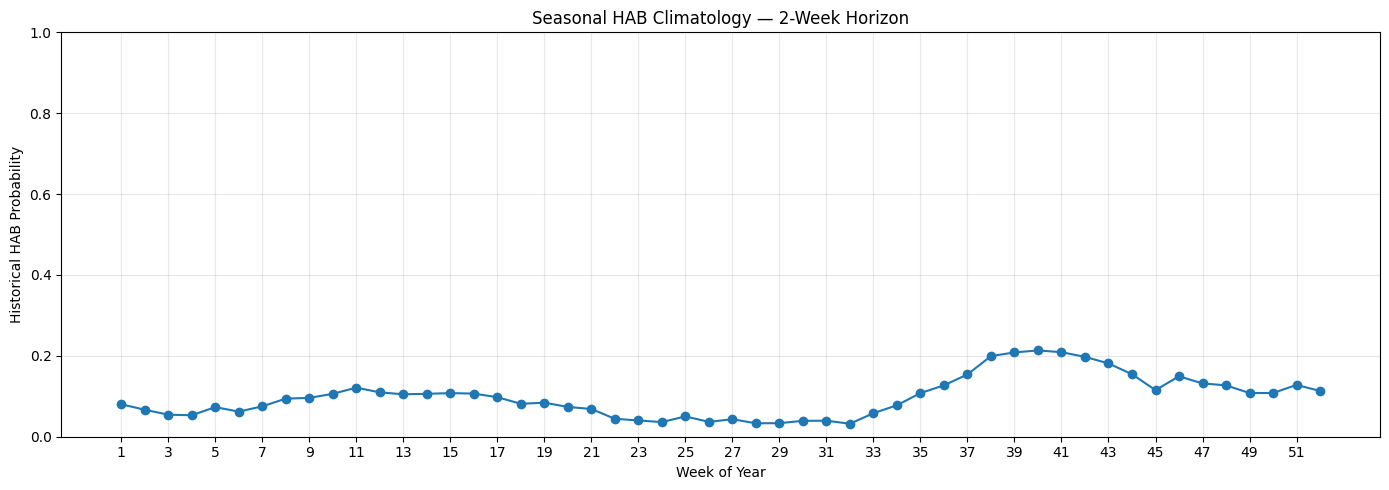

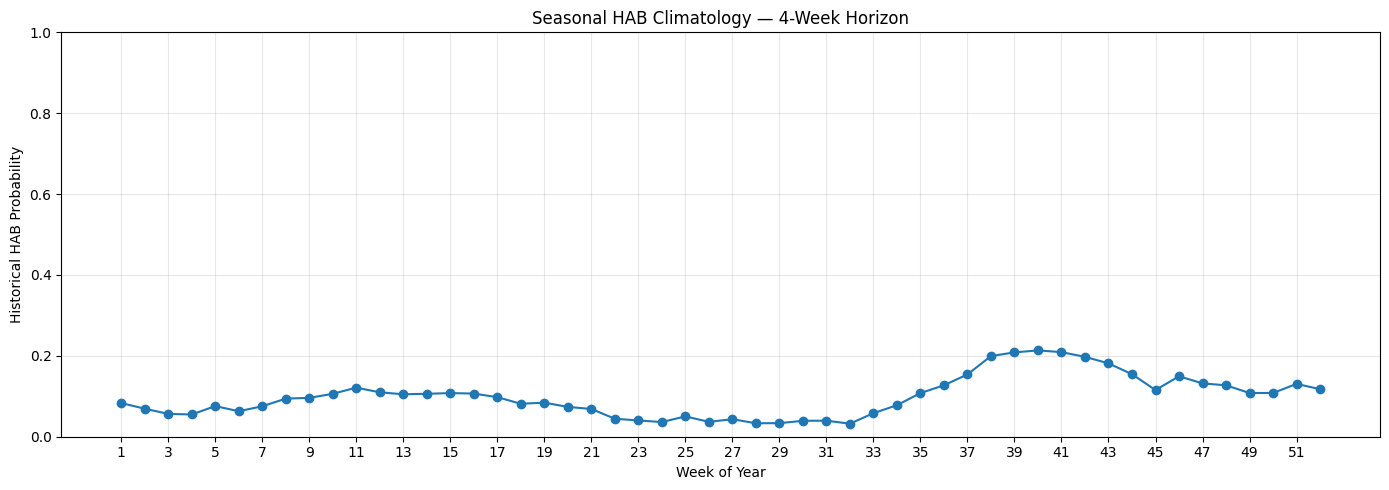

In [10]:
climatology_probabilities_df = pd.concat(
    climatology_probabilities,
    ignore_index=True
)

for horizon in HORIZONS:

    horizon_data = climatology_probabilities_df[
        climatology_probabilities_df["horizon"] == horizon
    ]

    # Average probabilities across evaluation folds
    average_climatology = (
        horizon_data
        .groupby("target_week")["HAB_probability"]
        .mean()
        .reset_index()
    )

    plt.figure(figsize=(14, 5))

    plt.plot(
        average_climatology["target_week"],
        average_climatology["HAB_probability"],
        marker="o"
    )

    plt.xlabel("Week of Year")
    plt.ylabel("Historical HAB Probability")

    plt.title(
        f"Seasonal HAB Climatology — {horizon}-Week Horizon"
    )

    plt.xticks(range(1, 53, 2))
    plt.ylim(0, 1)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

### Insights: Seasonal HAB Climatology Curves

- **There is a clear autumn peak.** Probability rises from week ~33 (mid-August), peaks at **~0.21 in weeks 38–43** (mid-September to late October), then declines through December. This matches the well-known late-summer/autumn red tide season on Florida's Gulf coast.
- **A minor secondary bump appears in weeks 10–16 (March–April),** at about 0.10–0.12.
- **Probability is lowest in weeks 22–32 (June to early August),** at about 0.03–0.05.
- **The curve is flat overall.** It never rises much above 0.21 on a 0–1 scale, so the seasonal signal is weak compared with how much bloom occurrence varies from year to year.
- **The three horizon curves are almost identical.** Shifting the target by 1–4 weeks barely changes the curve once it is smoothed over ±3 weeks.

## 11. Save Evaluation Results

Export the seasonal climatology evaluation outputs as CSV files.

The following results are saved:

- Fold-level evaluation metrics.
- Average evaluation metrics.
- Individual test predictions.
- Historical weekly HAB probabilities.

These files allow the results to be reused for further analysis and comparison with environmental-feature-based machine learning models.

In [11]:
# Save fold-level evaluation metrics
climatology_results_df.to_csv(
    f"{OUTPUT_DIR}/seasonal_climatology_fold_results.csv",
    index=False
)

# Save average evaluation metrics
climatology_summary_df.to_csv(
    f"{OUTPUT_DIR}/seasonal_climatology_summary.csv",
    index=False
)

# Save individual predictions
climatology_predictions_df = pd.concat(
    climatology_predictions,
    ignore_index=True
)

climatology_predictions_df.to_csv(
    f"{OUTPUT_DIR}/seasonal_climatology_predictions.csv",
    index=False
)

# Save historical weekly probabilities
climatology_probabilities_df.to_csv(
    f"{OUTPUT_DIR}/seasonal_climatology_probabilities.csv",
    index=False
)

print("Seasonal climatology results saved successfully.")

print("\nSaved files:")
print(os.listdir(OUTPUT_DIR))

Seasonal climatology results saved successfully.

Saved files:
['seasonal_climatology_fold_results.csv', 'seasonal_climatology_predictions.csv', 'seasonal_climatology_probabilities.csv', 'seasonal_climatology_summary.csv']


### Insights: Saved Outputs

- Four CSVs were written to `results/seasonal_climatology/`:
  - fold-level metrics
  - the summary table
  - week-by-week predictions
  - the weekly climatology tables
- The predictions file includes `constant_probability`, so later notebooks can compare against the constant-prevalence baseline without re-running this one.
- Section 19 writes a fifth file, the baseline comparison.

## 12. Analyze Predicted Probabilities and HAB Occurrences

Examine the relationship between predicted HAB probabilities and actual HAB occurrences for each evaluation year and forecasting horizon.

The diagnostic table includes:

- Number of observations.
- Actual HAB occurrences and occurrence rate.
- Predicted HAB classifications and prediction rate.
- Mean, maximum, and minimum predicted probabilities.
- Average predicted probability for actual HAB and non-HAB observations separately.

This analysis helps identify whether the climatology baseline assigns higher probabilities to observations that actually experience HAB occurrences.

In [12]:
diagnostic_results = []

for horizon in HORIZONS:

    target = TARGET_COLS[horizon]

    for year in TEST_YEARS:

        results = climatology_predictions_df[
            (climatology_predictions_df["horizon"] == horizon) &
            (climatology_predictions_df["test_year"] == year)
        ].copy()

        if results.empty:
            continue

        y_true = results["actual_HAB"]
        y_prob = results["predicted_probability"]
        y_pred = results["predicted_HAB"]

        diagnostic_results.append({
            "horizon": f"{horizon}-week",
            "year": year,
            "observations": len(results),

            "actual_blooms": int(y_true.sum()),
            "actual_bloom_rate": y_true.mean(),

            "predicted_blooms": int(y_pred.sum()),
            "predicted_bloom_rate": y_pred.mean(),

            "mean_probability": y_prob.mean(),
            "max_probability": y_prob.max(),
            "min_probability": y_prob.min(),

            "positive_probability_mean": (
                y_prob[y_true == 1].mean()
                if (y_true == 1).any() else np.nan
            ),

            "negative_probability_mean": (
                y_prob[y_true == 0].mean()
                if (y_true == 0).any() else np.nan
            )
        })

diagnostic_df = pd.DataFrame(diagnostic_results)

display(diagnostic_df.round(3))

,horizon,year,observations,actual_blooms,actual_bloom_rate,predicted_blooms,predicted_bloom_rate,mean_probability,max_probability,min_probability,positive_probability_mean,negative_probability_mean
0,1-week,2016,34,12,0.353,6,0.176,0.039,0.164,0.007,0.044,0.036
1,1-week,2017,24,6,0.250,0,0.000,0.054,0.155,0.013,0.094,0.041
2,1-week,2018,38,9,0.237,8,0.211,0.102,0.247,0.014,0.073,0.110
3,1-week,2019,29,0,0.000,2,0.069,0.079,0.146,0.031,NaN,0.079
4,1-week,2020,48,4,0.083,14,0.292,0.099,0.235,0.014,0.109,0.098
5,1-week,2021,39,11,0.282,19,0.487,0.117,0.221,0.035,0.081,0.131
6,1-week,2022,4,1,0.250,1,0.250,0.116,0.195,0.049,0.195,0.090
7,1-week,2023,5,0,0.000,1,0.200,0.101,0.130,0.059,NaN,0.101
8,1-week,2024,33,0,0.000,5,0.152,0.098,0.210,0.038,NaN,0.098
9,1-week,2025,37,7,0.189,8,0.216,0.098,0.203,0.034,0.122,0.093


### Insights: Probability vs. Occurrence Diagnostics

- **In 2018 and 2021 the model got the ordering backwards.** Bloom weeks received *lower* average probabilities than non-bloom weeks:
  - 2018: 0.073 vs 0.110
  - 2021: 0.081 vs 0.131

  The blooms in those years happened outside the usual autumn window.
- **It ranked correctly in 2017 (0.094 vs 0.041), 2022 and 2025 (0.122 vs 0.093).** In 2016 and 2020 the difference is negligible.
- **2016 was heavily under-forecast.** The actual bloom rate was 35%, but the mean predicted probability was only 0.039. Training data before 2016 contained few blooms, and the climatology could not anticipate a persistent bloom year.
- **2026 shows the largest over-forecast.** About half of its weeks were flagged as blooms (19–20 weeks) while none occurred.
- **2017 produced no bloom predictions.** Its highest probability (0.155) was below that fold's threshold (0.199), even though the probabilities ranked bloom weeks well.
- **Predicted probabilities stay in a narrow band (max ≤ 0.25) every year.** By design, the model cannot react to conditions in a particular year.

## 13. Examine the Distribution of Predicted Probabilities

Plot the distribution of predicted HAB probabilities across all evaluation observations for each forecasting horizon.

A vertical reference line shows the median fold-specific threshold selected from training data.

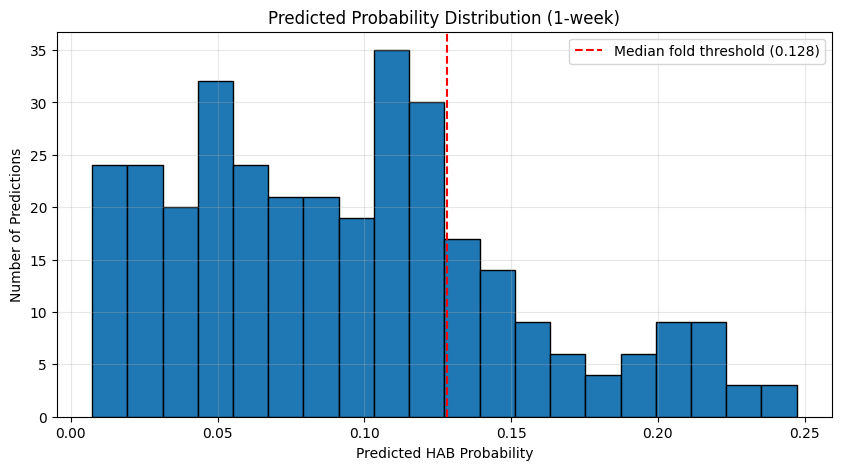

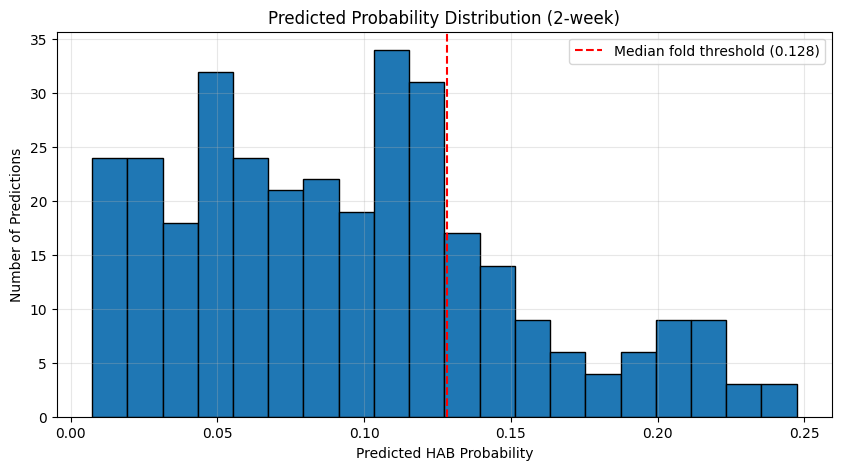

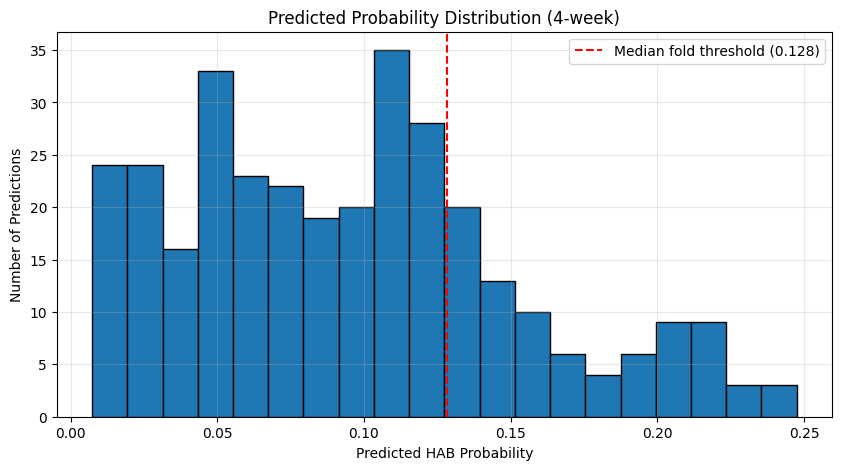

In [13]:
for horizon in HORIZONS:

    results = climatology_predictions_df[
        climatology_predictions_df["horizon"] == horizon
    ]

    median_threshold = results["threshold"].median()

    plt.figure(figsize=(10, 5))

    plt.hist(
        results["predicted_probability"],
        bins=20,
        edgecolor="black"
    )

    plt.axvline(
        median_threshold,
        linestyle="--",
        color="red",
        label=f"Median fold threshold ({median_threshold:.3f})"
    )

    plt.xlabel("Predicted HAB Probability")
    plt.ylabel("Number of Predictions")
    plt.title(f"Predicted Probability Distribution ({horizon}-week)")

    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

### Insights: Predicted Probability Distribution

- **All predicted probabilities fall between about 0.01 and 0.25.** The model is never confident about a bloom; nothing comes near 0.5.
- **Most predictions are between 0.02 and 0.13,** with a long right tail from the autumn-peak weeks.
- **The median fold threshold is ~0.128.** About a quarter of predictions sit above it (83 of 330 at the 1-week horizon), which is more than the actual bloom rate of ~15%. This drives the high false-alarm count.
- **Many predictions cluster just below the threshold (0.10–0.13),** so small changes to the threshold would change the predicted classes a lot.
- **The three horizons have almost the same distribution,** as expected for a calendar-based model.

## 14. Examine Evaluation Period Coverage

Assess the number of weekly observations available for each August–July evaluation period.

The coverage table reports the observed number of records and compares it with an approximate 52-week year.

This check helps identify incomplete evaluation periods that may affect the interpretation of annual performance metrics.

Note that 53 observations can occur within an August–July interval, and 2026 represents a partial evaluation period in the current dataset.

In [14]:
coverage_results = []

for year in TEST_YEARS:

    start = pd.Timestamp(year=year - 1, month=8, day=1)
    end = pd.Timestamp(year=year, month=8, day=1)

    year_data = dataset[
        (dataset["week_ending"] >= start) &
        (dataset["week_ending"] < end)
    ]

    coverage_results.append({
        "bloom_year": year,
        "observed_weeks": len(year_data),
        "expected_weeks": 52,
        "missing_weeks": max(0, 52 - len(year_data))
    })

coverage_df = pd.DataFrame(coverage_results)

display(coverage_df)

,bloom_year,observed_weeks,expected_weeks,missing_weeks
0,2016,53,52,0
1,2017,52,52,0
2,2018,52,52,0
3,2019,52,52,0
4,2020,52,52,0
5,2021,52,52,0
6,2022,53,52,0
7,2023,52,52,0
8,2024,52,52,0
9,2025,52,52,0


### Insights: Evaluation Period Coverage

- **Every bloom year from 2016 to 2025 has a full set of weekly rows** (52–53). 2026 is partial: 40 weeks, ending 2026-05-03.
- **Rows are not the same as labels.** The evaluation used far fewer weeks than this table shows: 24–48 per year, and only **4–5 in 2022 and 2023**. Many weeks have a missing target, probably because no sampling took place.
- **Fewer labelled weeks makes the metrics less reliable.** Scores for 2022, 2023 and 2017 (24 weeks) should be given little weight.
- **2026 is missing August–July coverage after early May,** so it includes none of the autumn peak season. Its zero-bloom result is not a full-year result.

## 15. Inspect Historical Weekly Probabilities

Examine the 20 calendar weeks with the highest estimated HAB probabilities for the 2021 evaluation fold at the 1-week forecasting horizon.

This provides a closer look at the seasonal patterns learned from the training data before the 2021 test period.

The table also reports the number of historical observations and HAB occurrences supporting each weekly probability estimate.

In [15]:
# Inspect the 2021 evaluation fold as an example
horizon = 1
year = 2021

weekly_probabilities = climatology_probabilities_df[
    (climatology_probabilities_df["horizon"] == horizon) &
    (climatology_probabilities_df["test_year"] == year)
].copy()

display(
    weekly_probabilities.sort_values(
        "HAB_probability",
        ascending=False
    ).head(20)
)

,target_week,HAB_occurrences,total_observations,raw_probability,window_occurrences,window_observations,HAB_probability,horizon,test_year
300,41,3,7,0.428571,11.0,44.0,0.221078,1,2021
299,40,2,7,0.285714,12.0,49.0,0.219292,1,2021
301,42,0,5,0.000000,10.0,40.0,0.218764,1,2021
297,38,2,8,0.250000,13.0,56.0,0.211185,1,2021
298,39,1,7,0.142857,12.0,52.0,0.208681,1,2021
302,43,2,6,0.333333,9.0,38.0,0.207046,1,2021
303,44,1,4,0.250000,7.0,36.0,0.172570,1,2021
305,46,0,5,0.000000,7.0,37.0,0.168898,1,2021
296,37,2,9,0.222222,10.0,58.0,0.160856,1,2021
306,47,0,5,0.000000,6.0,37.0,0.147622,1,2021


### Insights: Top Weekly Probabilities (2021 fold, 1-week)

- **All top-ranked weeks fall in weeks 35–52 (September–December).** The highest are weeks 38–43, with smoothed probabilities around 0.21–0.22.
- **A smaller secondary signal appears in weeks 10–11 (March),** at about 0.11–0.12.
- **The smoothing is clearly needed.** Each week has only 4–9 training observations, so raw rates are noisy:
  - Week 42 has a raw rate of **0.00** but a smoothed **0.219**, because its neighbours had blooms.
  - Week 41's raw **0.43** (3 of 7) is pulled down to **0.22**.
- **Each smoothed estimate pools 35–64 observations** across the ±3-week window, which makes the estimates stable.
- **The trade-off is that the highest probability is ~0.22.** The model never forecasts a bloom with confidence, which limits its sharpness.

## 16. Compare Probabilities for Actual HAB and Non-HAB Observations

Compare predicted probabilities for observations with actual HAB occurrences against observations without HAB occurrences.

The analysis reports the count, mean, median, minimum, and maximum predicted probabilities for each class.

If the climatology baseline effectively distinguishes the two classes, actual HAB observations should generally receive higher predicted probabilities than non-HAB observations.

This diagnostic is performed using the 2021 evaluation fold at the 1-week forecasting horizon.

In [16]:
# Compare predicted probabilities for positive and negative observations

horizon = 1
year = 2021

year_predictions = climatology_predictions_df[
    (climatology_predictions_df["horizon"] == horizon) &
    (climatology_predictions_df["test_year"] == year)
].copy()

year_predictions["actual_HAB"] = year_predictions["actual_HAB"].astype(int)

comparison = (
    year_predictions
    .groupby("actual_HAB")["predicted_probability"]
    .agg(
        count="count",
        mean_probability="mean",
        median_probability="median",
        min_probability="min",
        max_probability="max"
    )
)

display(comparison)

,count,mean_probability,median_probability,min_probability,max_probability
actual_HAB,,,,,
0,28,0.131055,0.123897,0.039176,0.221078
1,11,0.080752,0.068255,0.034979,0.147622


### Insights: Bloom vs. Non-Bloom Probabilities (2021, 1-week)

- **The classes are inverted.** The 11 bloom weeks averaged a predicted probability of **0.081** (median 0.068). The 28 non-bloom weeks averaged **0.131** (median 0.124).
- **No bloom week scored above 0.148,** while non-bloom weeks reached 0.221 (the autumn peak). So 2021's blooms fell in the climatological *low* season.
- **This lines up with the 2021 event.** The 2021 bloom in the Tampa Bay / Sarasota region happened mainly in late spring and summer, around the time of the Piney Point discharge. That is the trough of the seasonal curve (weeks 22–32).
- **A calendar-only model cannot predict an off-season bloom.** Forecasting blooms like this needs real-time environmental and persistence information.

## 17. Ranking Performance by Bloom Year

Calculate ROC-AUC and PR-AUC separately for each bloom year and forecasting horizon.

These metrics measure whether bloom weeks receive higher probabilities than non-bloom weeks, independent of the classification threshold. They are undefined for years with no bloom observations.

In [17]:
from sklearn.metrics import roc_auc_score, average_precision_score

ranking_results = []

for horizon in HORIZONS:
    for year in TEST_YEARS:

        year_data = climatology_predictions_df[
            (climatology_predictions_df["horizon"] == horizon) &
            (climatology_predictions_df["test_year"] == year)
        ].copy()

        y_true = year_data["actual_HAB"].astype(int)
        y_prob = year_data["predicted_probability"]

        if y_true.nunique() < 2:
            roc_auc = None
            pr_auc = None
        else:
            roc_auc = roc_auc_score(y_true, y_prob)
            pr_auc = average_precision_score(y_true, y_prob)

        ranking_results.append({
            "horizon": horizon,
            "bloom_year": year,
            "observations": len(year_data),
            "actual_blooms": int(y_true.sum()),
            "ROC_AUC": roc_auc,
            "PR_AUC": pr_auc
        })

ranking_df = pd.DataFrame(ranking_results)

display(
    ranking_df.round(3)
)

,horizon,bloom_year,observations,actual_blooms,ROC_AUC,PR_AUC
0,1,2016,34,12,0.466,0.445
1,1,2017,24,6,0.806,0.768
2,1,2018,38,9,0.268,0.189
3,1,2019,29,0,NaN,NaN
4,1,2020,48,4,0.537,0.124
5,1,2021,39,11,0.221,0.200
6,1,2022,4,1,1.000,1.000
7,1,2023,5,0,NaN,NaN
8,1,2024,33,0,NaN,NaN
9,1,2025,37,7,0.643,0.342


### Insights: Ranking Performance by Year

- **AUCs are undefined in 4 of 11 years** (2019, 2023, 2024, 2026) because those years have no labelled blooms. Only 7 years can be used to judge ranking.
- **The model ranks backwards (ROC-AUC < 0.5) in 3 major bloom years:** 2016 (0.47), 2018 (0.23–0.27) and 2021 (0.19–0.22). In those years blooms occurred in weeks the climatology considered low-risk.
- **Genuine skill appears in only 2017 (0.81) and 2025 (0.64).** 2020 is close to chance (0.47–0.54).
- **2022's perfect 1.0 is not meaningful.** It rests on 4 observations and 1 bloom.
- **Results are the same across horizons,** consistent with the earlier sections.
- **Bloom timing changes a lot from year to year,** so one fixed seasonal curve cannot rank weeks reliably.

## 18. Calculate Pooled Evaluation Metrics

Combine eligible out-of-fold predictions across evaluation years to calculate overall performance for each forecasting horizon.

The following metrics are reported:

- Number of evaluation observations.
- Number of actual HAB occurrences.
- Overall HAB occurrence rate.
- ROC-AUC.
- PR-AUC.
- Brier score.

Pooling predictions provides an overall assessment across the evaluation period rather than relying exclusively on annual metrics.

The Brier score measures the mean squared difference between predicted probabilities and actual binary outcomes. Lower values indicate better probability predictions.

Because years contribute according to their number of observations, pooled metrics are observation-weighted rather than averages of annual performance.

In [18]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

pooled_results = []

for horizon in HORIZONS:

    data = climatology_predictions_df[
        climatology_predictions_df["horizon"] == horizon
    ].copy()

    y_true = data["actual_HAB"].astype(int)
    y_prob = data["predicted_probability"]

    if y_true.nunique() == 2:
        roc_auc = roc_auc_score(y_true, y_prob)
        pr_auc = average_precision_score(y_true, y_prob)
    else:
        roc_auc = None
        pr_auc = None

    pooled_results.append({
        "horizon": horizon,
        "observations": len(data),
        "actual_blooms": int(y_true.sum()),
        "bloom_rate": y_true.mean(),
        "ROC_AUC": roc_auc,
        "PR_AUC": pr_auc,
        "Brier_score": brier_score_loss(y_true, y_prob)
    })

pooled_results_df = pd.DataFrame(pooled_results)

display(pooled_results_df.round(3))

,horizon,observations,actual_blooms,bloom_rate,ROC_AUC,PR_AUC,Brier_score
0,1,330,50,0.152,0.423,0.136,0.139
1,2,329,50,0.152,0.421,0.136,0.139
2,4,327,50,0.153,0.416,0.135,0.140


### Insights: Pooled Metrics

- **About 330 out-of-sample weeks with 50 blooms (15.2% prevalence)** at each horizon.
- **Pooled ROC-AUC is ~0.42, below random (0.5).** When all years are combined, bloom weeks tend to receive *lower* probabilities than non-bloom weeks.
- **PR-AUC (~0.136) is below the bloom rate (~0.152),** which again means no ranking skill.
- **The pooled AUC (0.42) is much lower than the mean annual AUC (~0.56, Section 8).** Two reasons:
  - Pooling also penalises differences *between* years. In heavy bloom years such as 2016 (35% bloom rate), the model still gave mean probabilities of ~0.04.
  - The annual average is lifted by the 4-observation 2022 fold.
- **Brier score is ~0.139.** For reference, always predicting the true pooled rate would give about 0.152 × 0.848 ≈ 0.129, so the probabilities are poorly calibrated even before skill is considered.
- **Horizon has almost no effect** (AUC 0.423 → 0.416 from 1 to 4 weeks).

## 19. Compare Seasonal Climatology Against a Constant-Prevalence Baseline

Compare the seasonal climatology model against a baseline that assigns every test week the bloom rate of its **training fold** (no test labels are used, so the comparison is strictly out-of-sample).

Metrics on the pooled predictions:

- Brier score (lower is better) and Brier skill score relative to constant prevalence (BSS > 0 means the seasonal pattern adds information).
- ROC-AUC and PR-AUC (higher is better; PR-AUC of a no-skill model ≈ bloom rate).

In [19]:
def pooled_scores(y_true, y_prob):
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob, dtype=float)
    both = len(np.unique(y_true)) == 2
    return {
        "brier": brier_score_loss(y_true, y_prob),
        "roc_auc": roc_auc_score(y_true, y_prob) if both else np.nan,
        "pr_auc": average_precision_score(y_true, y_prob) if both else np.nan,
    }


baseline_comparison = []

for horizon in HORIZONS:

    data = climatology_predictions_df[
        climatology_predictions_df["horizon"] == horizon
    ]
    y_true = data["actual_HAB"].astype(int)

    reference_brier = brier_score_loss(y_true, data["constant_probability"])

    for name, column in [
        ("Seasonal Climatology", "predicted_probability"),
        ("Constant Prevalence (train)", "constant_probability"),
    ]:
        scores = pooled_scores(y_true, data[column])
        baseline_comparison.append({
            "horizon": horizon,
            "model": name,
            "bloom_rate": y_true.mean(),
            **scores,
            "brier_skill_vs_constant": 1 - scores["brier"] / reference_brier,
        })

baseline_comparison_df = pd.DataFrame(baseline_comparison)

display(baseline_comparison_df.round(4))

baseline_comparison_df.to_csv(
    f"{OUTPUT_DIR}/seasonal_climatology_baseline_comparison.csv",
    index=False
)

,horizon,model,bloom_rate,brier,roc_auc,pr_auc,brier_skill_vs_constant
0,1,Seasonal Climatology,0.1515,0.1387,0.4226,0.1358,-0.0155
1,1,Constant Prevalence (train),0.1515,0.1365,0.2521,0.1076,0.0000
2,2,Seasonal Climatology,0.1520,0.1391,0.4211,0.1357,-0.0158
3,2,Constant Prevalence (train),0.1520,0.1369,0.2498,0.1077,0.0000
4,4,Seasonal Climatology,0.1529,0.1400,0.4157,0.1349,-0.0173
5,4,Constant Prevalence (train),0.1529,0.1377,0.2482,0.1078,0.0000


### Insights: Climatology vs. Constant Prevalence

- **Brier skill is negative at every horizon (−1.55% to −1.73%).** Seasonal climatology predicts *slightly worse* than giving every week the training-fold bloom rate. Adding the seasonal shape adds noise, not information.
- **Neither model ranks well.** Climatology's ROC-AUC (~0.42) beats constant prevalence (~0.25), but both are below 0.5. The constant model's AUC comes only from differences in training rates between folds; within a single year it would be exactly 0.5. So this gap is not evidence of skill.
- **PR-AUC (0.136 vs 0.108) is below the bloom rate (~0.152) for both models**, which confirms neither has meaningful ability to pick out bloom weeks.
- **Bottom line:** at this site, calendar week is not a useful predictor on its own. For Brier score, constant prevalence is the harder baseline to beat.

## 20. Overall Conclusions

1. **Calendar timing alone does not forecast blooms here.** Pooled ROC-AUC is about 0.42 and PR-AUC about 0.136, both below no-skill (0.5 and the 0.152 bloom rate). The Brier skill score against constant prevalence is about −1.6%.
2. **The seasonal signal is real but weak.** Historical bloom probability peaks in weeks ~38–43 (mid-September to late October) at only ~0.21. That is too flat to separate bloom weeks from non-bloom weeks.
3. **Year-to-year variability dominates.** Whether a given year has a bloom matters far more than when in the year it is. Of the 11 test years, 4 had no labelled blooms. Major events (2016, 2018, 2021) were missed or ranked backwards, and 2021's blooms fell in the climatological low season.
4. **Forecast horizon makes no difference.** Results at 1, 2 and 4 weeks are almost identical. This is expected because shifting the target date by up to 4 weeks barely moves it within a ±3-week smoothed curve.
5. **Some headline numbers are misleading.** The mean annual F1 (~0.30) and ROC-AUC (~0.56) are lifted by 2022, which has only 4 labelled weeks. Without 2022 they drop to ~0.18 and ~0.49. Mean accuracy (~0.71) is below what an "always no bloom" forecast would score (~0.85).
6. **What this means for the ML models.** Seasonal climatology sets a **low bar**. Environmental-feature models need to capture interannual drivers (e.g. bloom persistence from recent *K. brevis* counts, winds, nutrients) to show real skill. Constant prevalence is the stronger Brier benchmark to beat.